<a href="https://colab.research.google.com/github/shivamkumar359/3rd-SEM-CLASS-CODES/blob/main/ML/W6/WEEK_6_PRACTICAL_SESSION_BY_MITHUN_DJ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ==============
#  BOOSTING: ADD BOOST AND GRADIENT BOOSTING

# ==============

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

In [7]:
# ==================
# PART 1: CREATE DATSET
# =====================

print("PART 1: CREATE DATASET ")

X,y = make_classification(
    n_samples=500,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=0.8,
    random_state=42
)

PART 1: CREATE DATASET 


In [10]:
X

array([[ 8.08454985e-01, -8.47009753e-01],
       [ 1.26021382e-01,  3.02540973e-01],
       [ 8.24204975e-01, -1.59714286e+00],
       [-7.81199330e-02,  1.25937142e+00],
       [-1.60900267e-01,  1.82369370e-01],
       [ 1.06221796e+00, -5.60726298e-01],
       [ 5.51010599e-01,  6.79395978e-01],
       [-9.49552409e-01, -3.31748509e-01],
       [ 1.97777110e-01,  4.94304161e-01],
       [ 1.40117355e+00,  1.11994147e+00],
       [ 2.45997363e+00, -2.72346297e+00],
       [ 1.19309699e+00, -2.41327073e+00],
       [ 1.25885001e-01, -1.32748814e+00],
       [ 3.54900000e-01,  4.62973369e-01],
       [-6.38788576e-02,  1.35068994e+00],
       [ 5.92352807e-01,  6.42255922e-01],
       [ 7.46116447e-01,  7.05699594e-01],
       [-9.44241589e-02, -2.29081227e-01],
       [-2.00538715e-01, -1.20426119e+00],
       [ 2.08144543e+00, -1.17667072e+00],
       [ 1.58152502e+00, -1.17344458e+00],
       [ 1.53498800e+00,  1.29257599e+00],
       [ 1.29176434e+00, -1.74288103e+00],
       [ 8.

In [11]:
y

array([0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0,
       1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1,

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


PART 2 : VISUALIZEE DATA


Text(0.5, 1.0, 'Customer loan Classification ')

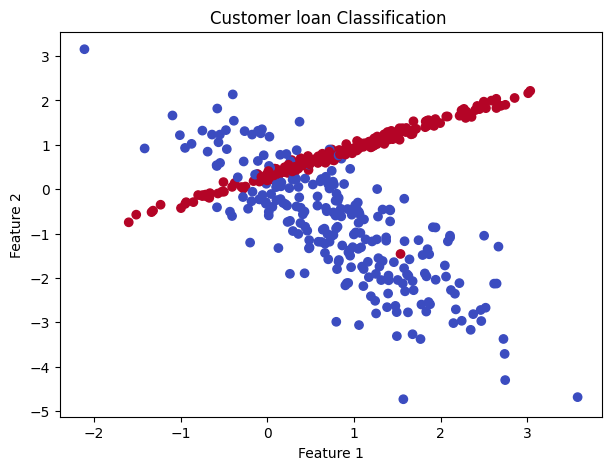

In [32]:
# PART 2 : VISUALIZEE DATA
#-------------------------------------

print("PART 2 : VISUALIZEE DATA")

plt.figure(figsize=(7,5))
plt.scatter(X[:,0], X[:,1],c=y, cmap="coolwarm")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Customer loan Classification ")

In [27]:
# ============================================================
# PART 3: TRAIN A WEAK LEARNER
# ============================================================
print("\nPART 3: WEAK LEARNER")
weak_model = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)
weak_model.fit(X_train, y_train)
weak_pred = weak_model.predict(X_test)


PART 3: WEAK LEARNER


In [34]:
weak_accuracy = accuracy_score(y_test, weak_pred)

# Train adaboost

In [31]:
# part 4

ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

In [25]:
ada_model.fit(X_train,y_train)
ada_pred = ada_model.predict(X_test)

NameError: name 'ada_model' is not defined

In [26]:
# ============================================================
# PART 7: INSPECT LEARNER WEIGHTS AND ERRORS
# ============================================================

print("\nPART 7: LEARNER WEIGHTS")

learner_info = pd.DataFrame({
    "Learner": range(1, len(ada_model.estimators_) + 1),
    "Weight": ada_model.estimator_weights_,
    "Error": ada_model.estimator_errors_
})

print(learner_info.head(10).round(3))

plt.figure(figsize=(8, 4))
plt.plot(
    learner_info["Learner"],
    learner_info["Weight"],
    marker="o"
)
plt.xlabel("Learner Number")
plt.ylabel("Learner Weight")
plt.title("Contribution of Weak Learners")
plt.grid(True)
plt.show()


PART 6: LEARNING CURVE


NameError: name 'ada_model' is not defined

In [ ]:
# ============================================================
# PART 7: INSPECT LEARNER WEIGHTS AND ERRORS
# ============================================================

print("\nPART 7: LEARNER WEIGHTS")

learner_info = pd.DataFrame({
    "Learner": range(1, len(ada_model.estimators_) + 1),
    "Weight": ada_model.estimator_weights_,
    "Error": ada_model.estimator_errors_
})

print(learner_info.head(10).round(3))

plt.figure(figsize=(8, 4))
plt.plot(
    learner_info["Learner"],
    learner_info["Weight"],
    marker="o"
)
plt.xlabel("Learner Number")
plt.ylabel("Learner Weight")
plt.title("Contribution of Weak Learners")
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# PART 8: COMPARE LEARNING RATES
# ============================================================

print("\nPART 8: LEARNING RATE EXPERIMENT")

rates = [0.1, 0.5, 1.0, 1.5]
rate_results = []

for rate in rates:
    model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        learning_rate=rate,
        random_state=42
    )

    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    rate_results.append({
        "Learning Rate": rate,
        "Accuracy": accuracy_score(y_test, prediction)
    })

rate_df = pd.DataFrame(rate_results)
print(rate_df.round(3))

plt.figure(figsize=(7, 4))
plt.plot(
    rate_df["Learning Rate"],
    rate_df["Accuracy"],
    marker="o"
)
plt.xlabel("Learning Rate")
plt.ylabel("Test Accuracy")
plt.title("Effect of Learning Rate")
plt.grid(True)
plt.show()